# E3 — Physicochemical landscape

## Objective

Characterize the **physicochemical and biophysical properties** associated with phage lytic proteins
and determine how those properties depend on the negative background and on the clean lytic subtype.

E3 deliberately **does not repeat amino-acid composition**. AAC frequencies and sequence-complexity
signals were already analyzed in E2. Here, Roxy is used only to estimate descriptors representing
physicochemical, electrostatic, order/disorder, structural-propensity, and AAIndex-derived properties.

## Comparison contract

Inferential comparisons use the mutually exclusive `sequence_state` from frozen E0.

### Global contrasts

1. `P_core` vs `N_easy`
2. `P_core` vs `N_hard`
3. `P_core` vs `N_mixed`, where `N_mixed = N_easy ∪ N_hard`
4. `N_easy` vs `N_hard` as a background-diagnostic contrast

### Clean subtype contrasts

Only curated `P_core` sequences assigned to one clean subtype are used:

1. Endolysin vs Depolymerase
2. Endolysin vs VAL
3. Depolymerase vs VAL

Unlabeled and challenge states remain available for descriptive summaries but are not treated as
confirmed biological classes.

## Physicochemical feature contract

The E3 panel contains **27 non-AAC descriptors**:

### Global physicochemical properties
- molecular weight
- aliphatic index
- mean and SD hydropathy
- mean and SD polarity
- aromatic fraction
- hydrophobic fraction
- charged fraction
- Boman index
- net charge at pH 7
- fraction of charged residues
- NCPR
- donors per residue
- acceptors per residue

### Electrostatic properties
- net charge at pH 5
- net charge at pH 9

### Order/disorder properties
- disorder fraction
- order fraction
- flexibility fraction

### Structural propensity
- helix propensity
- sheet propensity
- turn propensity

### AAIndex-derived residue properties
- ANDN920101
- ARGP820101
- KYTJ820101
- FAUJ880104

`global_basic_shannon_entropy` is intentionally excluded because sequence entropy/complexity belongs
to E2. The 20 AAC frequencies are also excluded entirely.

Molecular weight is retained because it is a real physicochemical property, but it is explicitly marked
as a **direct length-sensitive property**. Descriptor–length Spearman associations are calculated for
all descriptors, and ranking tables include both unrestricted ranks and ranks excluding direct length proxies.

## Statistics

For each descriptor:

- descriptive distributions by evidence state and subtype;
- Kruskal–Wallis omnibus tests;
- Mann–Whitney U pairwise tests;
- Cliff's delta;
- Benjamini–Hochberg FDR;
- median differences;
- descriptor correlation/redundancy;
- association with sequence length;
- global and subtype rankings based on effect magnitude and cross-background stability.

The principal interpretation should emphasize effect size, background dependence, subtype dependence,
and redundancy rather than statistical significance alone.

In [1]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu, kruskal

from IPython.display import display

import roxy
from roxy import DESCRIPTOR_REGISTRY

sns.set_theme(
    context="notebook",
    style="ticks",
    font_scale=1.05,
)

pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 220)


def detect_roxy_version():
    module_version = getattr(roxy, "__version__", None)

    if module_version:
        return str(module_version)

    for distribution_name in ["roxy", "krenai-roxy"]:
        try:
            return version(distribution_name)
        except PackageNotFoundError:
            pass

    return "unknown"


ROXY_VERSION = detect_roxy_version()
print(f"Roxy version: {ROXY_VERSION}")

Roxy version: 0.2.0


## 1. Paths and frozen E0 input

In [2]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "EDA" else cwd

E0_PATH = (
    PROJECT_ROOT
    / "EDA_results"
    / "E0"
    / "phagelytic_eda_universe.csv"
)

RESULT_DIR = PROJECT_ROOT / "EDA_results" / "E3"
FIGURE_DIR = RESULT_DIR / "figures"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_PATH = RESULT_DIR / "physicochemical_descriptors.parquet"
FEATURE_MANIFEST_PATH = RESULT_DIR / "physicochemical_feature_manifest.tsv"
METADATA_PATH = RESULT_DIR / "physicochemical_metadata.json"

STATISTICS_PATH = RESULT_DIR / "descriptor_statistics.tsv"
OMNIBUS_PATH = RESULT_DIR / "descriptor_omnibus.tsv"
GLOBAL_EFFECTS_PATH = RESULT_DIR / "global_descriptor_effects.tsv"
SUBTYPE_EFFECTS_PATH = RESULT_DIR / "subtype_descriptor_effects.tsv"
CORRELATIONS_PATH = RESULT_DIR / "descriptor_correlations.tsv"
REDUNDANCY_PATH = RESULT_DIR / "descriptor_redundancy_pairs.tsv"
LENGTH_ASSOCIATION_PATH = RESULT_DIR / "descriptor_length_association.tsv"
RANKINGS_PATH = RESULT_DIR / "descriptor_rankings.tsv"

if not E0_PATH.is_file():
    raise FileNotFoundError(
        f"Frozen E0 input not found: {E0_PATH}"
    )

print(f"Project root : {PROJECT_ROOT}")
print(f"E0 input     : {E0_PATH}")
print(f"E3 results   : {RESULT_DIR}")

Project root : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
E0 input     : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E0/phagelytic_eda_universe.csv
E3 results   : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3


In [3]:
e0 = pd.read_csv(
    E0_PATH,
    dtype={
        "sequence_uid": str,
        "sequence": str,
        "sequence_state": str,
        "phage_lytic": str,
        "phage_lytic_subtype": str,
        "clean_subtype": str,
    },
    low_memory=False,
)

EXPECTED_ROWS = 442_329

assert len(e0) == EXPECTED_ROWS, (
    f"Unexpected E0 size: {len(e0):,}"
)

assert e0["sequence_uid"].notna().all()
assert e0["sequence"].notna().all()
assert e0["sequence_uid"].is_unique
assert e0["sequence"].is_unique

assert (
    e0["sequence"].str.len()
    == e0["sequence_length"]
).all()

print(
    f"Frozen exact-sequence universe: "
    f"{len(e0):,}"
)

display(
    e0["sequence_state"]
    .value_counts()
    .rename("n")
    .to_frame()
)

Frozen exact-sequence universe: 442,329


,n
sequence_state,
U_explicit,228075
U_other_unresolved,132145
N_easy,54711
P_core,11867
challenge_ambiguous_structural,10885
N_hard,4327
challenge_lytic_related,319


## 2. E3 physicochemical descriptor contract

In [4]:
# E3 intentionally excludes AAC and entropy/complexity descriptors.
ROXY_DESCRIPTOR_KEYS = [
    "global_basic",
    "charge",
    "order_disorder",
    "structural_propensity",
    "aaindex",
]

available_descriptors = set(DESCRIPTOR_REGISTRY)

missing_descriptor_keys = [
    key
    for key in ROXY_DESCRIPTOR_KEYS
    if key not in available_descriptors
]

if missing_descriptor_keys:
    raise KeyError(
        "The installed Roxy version does not expose the required "
        "physicochemical descriptor families: "
        + ", ".join(missing_descriptor_keys)
        + "\nAvailable registry keys:\n"
        + ", ".join(sorted(available_descriptors))
    )


PHYSICOCHEMICAL_FEATURES = [
    # Global physicochemical properties
    "global_basic_molecular_weight",
    "global_basic_aliphatic_index",
    "global_basic_hydropathy_mean",
    "global_basic_hydropathy_std",
    "global_basic_polarity_mean",
    "global_basic_polarity_std",
    "global_basic_aromatic_fraction",
    "global_basic_hydrophobic_fraction",
    "global_basic_charged_fraction",
    "global_basic_boman_index",
    "global_basic_net_charge_ph7",
    "global_basic_fcr",
    "global_basic_ncpr",
    "global_basic_donors_per_residue",
    "global_basic_acceptors_per_residue",

    # Charge at alternative pH values
    "charge_net_charge_ph5p0",
    "charge_net_charge_ph9p0",

    # Order / disorder
    "order_disorder_disorder_fraction",
    "order_disorder_order_fraction",
    "order_disorder_flexibility_fraction",

    # Structural propensity
    "structural_propensity_helix_mean",
    "structural_propensity_sheet_mean",
    "structural_propensity_turn_mean",

    # AAIndex-derived residue properties
    "aaindex_ANDN920101_mean",
    "aaindex_ARGP820101_mean",
    "aaindex_KYTJ820101_mean",
    "aaindex_FAUJ880104_mean",
]

if len(PHYSICOCHEMICAL_FEATURES) != 27:
    raise RuntimeError(
        "Internal E3 contract must contain exactly 27 descriptors."
    )


FAMILY_BY_FEATURE = {}

for feature in PHYSICOCHEMICAL_FEATURES:
    if feature.startswith("global_basic_"):
        family = "global_basic"
    elif feature.startswith("charge_"):
        family = "charge"
    elif feature.startswith("order_disorder_"):
        family = "order_disorder"
    elif feature.startswith("structural_propensity_"):
        family = "structural_propensity"
    elif feature.startswith("aaindex_"):
        family = "aaindex"
    else:
        raise RuntimeError(
            f"Could not classify E3 feature: {feature}"
        )

    FAMILY_BY_FEATURE[feature] = family


DIRECT_LENGTH_PROXY_FEATURES = {
    "global_basic_molecular_weight",
}

PRIMARY_RANKING_FEATURES = [
    feature
    for feature in PHYSICOCHEMICAL_FEATURES
    if feature not in DIRECT_LENGTH_PROXY_FEATURES
]

print("E3 physicochemical feature contract")
print(f"Total descriptors: {len(PHYSICOCHEMICAL_FEATURES)}")
print(f"Primary ranking descriptors: {len(PRIMARY_RANKING_FEATURES)}")

display(
    pd.Series(FAMILY_BY_FEATURE)
    .rename("family")
    .value_counts()
    .rename("n_features")
    .to_frame()
)

E3 physicochemical feature contract
Total descriptors: 27
Primary ranking descriptors: 26


,n_features
family,
global_basic,15
aaindex,4
order_disorder,3
structural_propensity,3
charge,2


## 3. Compute or reuse physicochemical descriptors

In [5]:
CHUNK_SIZE = 20_000


def uid_contract_sha256(values):
    digest = hashlib.sha256()

    for value in values:
        digest.update(str(value).encode("utf-8"))
        digest.update(b"\n")

    return digest.hexdigest()


E0_UID_SHA256 = uid_contract_sha256(
    e0["sequence_uid"]
)


def _to_pandas(frame):
    if isinstance(frame, pd.DataFrame):
        return frame.copy()

    if hasattr(frame, "to_pandas"):
        return frame.to_pandas()

    return pd.DataFrame(frame)


def _normalize_roxy_output(
    frame,
    ids,
    descriptor_key,
):
    out = _to_pandas(frame)

    if len(out) != len(ids):
        raise RuntimeError(
            f"Roxy descriptor '{descriptor_key}' returned "
            f"{len(out):,} rows for {len(ids):,} sequences."
        )

    id_candidates = [
        col
        for col in [
            "sequence_uid",
            "id",
            "sequence_id",
            "name",
        ]
        if col in out.columns
    ]

    if id_candidates:
        id_col = id_candidates[0]

        out = out.rename(
            columns={id_col: "sequence_uid"}
        )

        observed_ids = (
            out["sequence_uid"]
            .astype(str)
            .tolist()
        )

        expected_ids = [
            str(value)
            for value in ids
        ]

        if observed_ids != expected_ids:
            raise RuntimeError(
                f"Roxy descriptor '{descriptor_key}' "
                "changed sequence order or IDs."
            )

    else:
        out.insert(
            0,
            "sequence_uid",
            [str(value) for value in ids],
        )

    for col in ["sequence", "seq"]:
        if col in out.columns:
            out = out.drop(columns=col)

    feature_cols = [
        col
        for col in out.columns
        if col != "sequence_uid"
    ]

    if not feature_cols:
        raise RuntimeError(
            f"Roxy descriptor '{descriptor_key}' "
            "returned no feature columns."
        )

    return out[["sequence_uid"] + feature_cols]

In [6]:
reuse_cache = (
    FEATURE_PATH.is_file()
    and FEATURE_MANIFEST_PATH.is_file()
)

if reuse_cache:
    print(
        "Reusing existing E3 physicochemical cache."
    )

    physicochemical = pd.read_parquet(
        FEATURE_PATH
    )

    feature_manifest = pd.read_csv(
        FEATURE_MANIFEST_PATH,
        sep="\t",
    )

    if len(physicochemical) != len(e0):
        raise RuntimeError(
            f"Cached physicochemical table has "
            f"{len(physicochemical):,} rows; "
            f"E0 has {len(e0):,}."
        )

    if "sequence_uid" not in physicochemical.columns:
        raise RuntimeError(
            "Cached physicochemical table lacks sequence_uid."
        )

    if not physicochemical["sequence_uid"].is_unique:
        raise RuntimeError(
            "Cached physicochemical table contains duplicated sequence_uid."
        )

    e0_uid_index = pd.Index(
        e0["sequence_uid"].astype(str)
    )

    cache_uid_index = pd.Index(
        physicochemical["sequence_uid"].astype(str)
    )

    missing_from_cache = e0_uid_index.difference(
        cache_uid_index
    )

    extra_in_cache = cache_uid_index.difference(
        e0_uid_index
    )

    if len(missing_from_cache) or len(extra_in_cache):
        raise RuntimeError(
            "Cached physicochemical table does not match frozen E0. "
            f"Missing: {len(missing_from_cache):,}; "
            f"extra: {len(extra_in_cache):,}."
        )

    missing_features = [
        feature
        for feature in PHYSICOCHEMICAL_FEATURES
        if feature not in physicochemical.columns
    ]

    if missing_features:
        raise RuntimeError(
            "Cached physicochemical table is missing required features:\n"
            + "\n".join(missing_features)
        )

else:
    print(
        "Computing E3 physicochemical descriptors from frozen E0."
    )

    descriptor_objects = {
        key: DESCRIPTOR_REGISTRY[key]()
        for key in ROXY_DESCRIPTOR_KEYS
    }

    chunks = []

    for start in range(
        0,
        len(e0),
        CHUNK_SIZE,
    ):
        stop = min(
            start + CHUNK_SIZE,
            len(e0),
        )

        chunk = e0.iloc[start:stop]

        ids = (
            chunk["sequence_uid"]
            .astype(str)
            .tolist()
        )

        sequences = (
            chunk["sequence"]
            .astype(str)
            .tolist()
        )

        chunk_features = pd.DataFrame(
            {"sequence_uid": ids}
        )

        for descriptor_key, descriptor in descriptor_objects.items():
            raw = descriptor.compute(
                sequences,
                ids=ids,
            )

            normalized = _normalize_roxy_output(
                raw,
                ids=ids,
                descriptor_key=descriptor_key,
            )

            selected_from_family = [
                feature
                for feature in PHYSICOCHEMICAL_FEATURES
                if FAMILY_BY_FEATURE[feature] == descriptor_key
            ]

            missing_selected = [
                feature
                for feature in selected_from_family
                if feature not in normalized.columns
            ]

            if missing_selected:
                raise RuntimeError(
                    f"Roxy family '{descriptor_key}' did not return "
                    "required E3 features:\n"
                    + "\n".join(missing_selected)
                )

            normalized = normalized[
                ["sequence_uid"] + selected_from_family
            ]

            chunk_features = chunk_features.merge(
                normalized,
                on="sequence_uid",
                how="left",
                validate="one_to_one",
            )

        chunks.append(chunk_features)

        print(
            f"Computed {stop:,}/{len(e0):,} sequences"
        )

    physicochemical = pd.concat(
        chunks,
        ignore_index=True,
    )

    assert len(physicochemical) == len(e0)
    assert physicochemical["sequence_uid"].is_unique

    physicochemical.to_parquet(
        FEATURE_PATH,
        index=False,
    )


# Normalize infinities and enforce complete selected panel.
physicochemical[
    PHYSICOCHEMICAL_FEATURES
] = physicochemical[
    PHYSICOCHEMICAL_FEATURES
].replace(
    [np.inf, -np.inf],
    np.nan,
)

null_counts = (
    physicochemical[
        PHYSICOCHEMICAL_FEATURES
    ]
    .isna()
    .sum()
)

null_counts = null_counts[
    null_counts > 0
]

if len(null_counts):
    raise RuntimeError(
        "Selected E3 physicochemical descriptors contain "
        "unexpected missing values:\n"
        + null_counts.to_string()
    )


feature_manifest = pd.DataFrame(
    {
        "roxy_version": ROXY_VERSION,
        "feature": PHYSICOCHEMICAL_FEATURES,
        "descriptor_family": [
            FAMILY_BY_FEATURE[feature]
            for feature in PHYSICOCHEMICAL_FEATURES
        ],
        "direct_length_proxy": [
            feature in DIRECT_LENGTH_PROXY_FEATURES
            for feature in PHYSICOCHEMICAL_FEATURES
        ],
        "primary_ranking_eligible": [
            feature in PRIMARY_RANKING_FEATURES
            for feature in PHYSICOCHEMICAL_FEATURES
        ],
    }
)

feature_manifest.to_csv(
    FEATURE_MANIFEST_PATH,
    sep="\t",
    index=False,
)

metadata = {
    "e0_rows": int(len(e0)),
    "e0_uid_sha256": E0_UID_SHA256,
    "roxy_version": ROXY_VERSION,
    "descriptor_keys": ROXY_DESCRIPTOR_KEYS,
    "feature_count": len(PHYSICOCHEMICAL_FEATURES),
    "aac_included": False,
    "entropy_complexity_included": False,
    "direct_length_proxy_features": sorted(
        DIRECT_LENGTH_PROXY_FEATURES
    ),
}

METADATA_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print()
print(f"Rows             : {len(physicochemical):,}")
print(f"E3 descriptors   : {len(PHYSICOCHEMICAL_FEATURES)}")
print(f"Roxy version     : {ROXY_VERSION}")

display(
    feature_manifest
    .groupby("descriptor_family")
    .size()
    .rename("n_features")
    .to_frame()
)

Computing E3 physicochemical descriptors from frozen E0.
Computed 20,000/442,329 sequences
Computed 40,000/442,329 sequences
Computed 60,000/442,329 sequences
Computed 80,000/442,329 sequences
Computed 100,000/442,329 sequences
Computed 120,000/442,329 sequences
Computed 140,000/442,329 sequences
Computed 160,000/442,329 sequences
Computed 180,000/442,329 sequences
Computed 200,000/442,329 sequences
Computed 220,000/442,329 sequences
Computed 240,000/442,329 sequences
Computed 260,000/442,329 sequences
Computed 280,000/442,329 sequences
Computed 300,000/442,329 sequences
Computed 320,000/442,329 sequences
Computed 340,000/442,329 sequences
Computed 360,000/442,329 sequences
Computed 380,000/442,329 sequences
Computed 400,000/442,329 sequences
Computed 420,000/442,329 sequences
Computed 440,000/442,329 sequences
Computed 442,329/442,329 sequences

Rows             : 442,329
E3 descriptors   : 27
Roxy version     : 0.2.0


,n_features
descriptor_family,
aaindex,4
charge,2
global_basic,15
order_disorder,3
structural_propensity,3


## 4. Join frozen labels and define cohorts

In [7]:
analysis = e0[
    [
        "sequence_uid",
        "sequence_state",
        "phage_lytic",
        "phage_lytic_subtype",
        "clean_subtype",
        "sequence_length",
    ]
].merge(
    physicochemical,
    on="sequence_uid",
    how="left",
    validate="one_to_one",
)

assert len(analysis) == len(e0)

if analysis[
    PHYSICOCHEMICAL_FEATURES
].isna().any().any():
    raise RuntimeError(
        "E3 descriptor table contains missing values after E0 join."
    )


P = analysis.loc[
    analysis["sequence_state"].eq("P_core")
].copy()

N_EASY = analysis.loc[
    analysis["sequence_state"].eq("N_easy")
].copy()

N_HARD = analysis.loc[
    analysis["sequence_state"].eq("N_hard")
].copy()

N_MIXED = analysis.loc[
    analysis["sequence_state"].isin(
        ["N_easy", "N_hard"]
    )
].copy()


CLEAN_SUBTYPES = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]

P_CLEAN = P.loc[
    P["clean_subtype"].isin(CLEAN_SUBTYPES)
].copy()


print("Global cohorts")
print(f"P_core  : {len(P):,}")
print(f"N_easy  : {len(N_EASY):,}")
print(f"N_hard  : {len(N_HARD):,}")
print(f"N_mixed : {len(N_MIXED):,}")

print()
print("Clean P_core subtypes")

display(
    P_CLEAN["clean_subtype"]
    .value_counts()
    .rename("n")
    .to_frame()
)

Global cohorts
P_core  : 11,867
N_easy  : 54,711
N_hard  : 4,327
N_mixed : 59,038

Clean P_core subtypes


,n
clean_subtype,
endolysin,9888
depolymerase,712
virion_associated_lytic_enzyme,241


## 5. Descriptive statistics

In [8]:
PRIMARY_ORDER = [
    "P_core",
    "N_easy",
    "N_hard",
    "U_explicit",
    "U_other_unresolved",
    "challenge_lytic_related",
    "challenge_ambiguous_structural",
]

CORE_SUBTYPE_ORDER = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
    "multiple_nonexclusive",
    "other_phage_envelope_lytic_enzyme",
]


def summarize_descriptors(
    data,
    group_col,
    section,
    group_order,
):
    rows = []

    for group in group_order:
        group_df = data.loc[
            data[group_col].eq(group)
        ]

        if len(group_df) == 0:
            continue

        for feature in PHYSICOCHEMICAL_FEATURES:
            values = pd.to_numeric(
                group_df[feature],
                errors="coerce",
            ).dropna()

            rows.append(
                {
                    "section": section,
                    "group": group,
                    "feature": feature,
                    "descriptor_family": FAMILY_BY_FEATURE[feature],
                    "direct_length_proxy": (
                        feature in DIRECT_LENGTH_PROXY_FEATURES
                    ),
                    "n": len(values),
                    "mean": values.mean(),
                    "std": values.std(),
                    "min": values.min(),
                    "q05": values.quantile(0.05),
                    "q25": values.quantile(0.25),
                    "median": values.median(),
                    "q75": values.quantile(0.75),
                    "q95": values.quantile(0.95),
                    "max": values.max(),
                }
            )

    return pd.DataFrame(rows)


primary_statistics = summarize_descriptors(
    analysis,
    group_col="sequence_state",
    section="primary_state",
    group_order=PRIMARY_ORDER,
)

subtype_statistics = summarize_descriptors(
    P,
    group_col="phage_lytic_subtype",
    section="P_core_subtype",
    group_order=CORE_SUBTYPE_ORDER,
)

descriptor_statistics = pd.concat(
    [
        primary_statistics,
        subtype_statistics,
    ],
    ignore_index=True,
)

descriptor_statistics.to_csv(
    STATISTICS_PATH,
    sep="\t",
    index=False,
)

print(f"Saved: {STATISTICS_PATH}")
display(descriptor_statistics.head())

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/descriptor_statistics.tsv


,section,group,feature,descriptor_family,direct_length_proxy,n,mean,std,min,q05,q25,median,q75,q95,max
0,primary_state,P_core,global_basic_molecular_weight,global_basic,True,11867,41966.197051,32965.482460,1871.075000,15479.322000,21867.360000,31687.710000,48732.460000,110619.101000,547342.770000
1,primary_state,P_core,global_basic_aliphatic_index,global_basic,False,11867,77.697215,9.556388,21.157407,62.888744,71.978417,77.515152,83.050097,93.203888,154.705882
2,primary_state,P_core,global_basic_hydropathy_mean,global_basic,False,11867,-0.356397,0.207031,-1.839474,-0.663794,-0.473301,-0.371338,-0.250287,-0.016649,1.131200
3,primary_state,P_core,global_basic_hydropathy_std,global_basic,False,11867,2.942103,0.104743,2.278348,2.766466,2.878034,2.942877,3.009274,3.112534,3.423128
4,primary_state,P_core,global_basic_polarity_mean,global_basic,False,11867,12.793729,1.853639,4.518189,9.645957,11.742019,12.850389,13.917593,15.633462,24.619474


## 6. Statistical helpers

In [9]:
def benjamini_hochberg(p_values):
    p = np.asarray(
        p_values,
        dtype=float,
    )

    adjusted = np.full(
        len(p),
        np.nan,
        dtype=float,
    )

    finite_mask = np.isfinite(p)

    if not finite_mask.any():
        return adjusted

    finite_p = p[finite_mask]
    n = len(finite_p)

    order = np.argsort(finite_p)
    ranked = finite_p[order]

    ranked_adjusted = (
        ranked
        * n
        / np.arange(1, n + 1)
    )

    ranked_adjusted = np.minimum.accumulate(
        ranked_adjusted[::-1]
    )[::-1]

    ranked_adjusted = np.clip(
        ranked_adjusted,
        0,
        1,
    )

    finite_adjusted = np.empty(
        n,
        dtype=float,
    )

    finite_adjusted[order] = ranked_adjusted
    adjusted[finite_mask] = finite_adjusted

    return adjusted


def finite_values(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    ).to_numpy(dtype=float)

    return values[
        np.isfinite(values)
    ]


def pairwise_effect_table(
    group_a_df,
    group_b_df,
    group_a,
    group_b,
    contrast,
    contrast_purpose,
):
    rows = []

    for feature in PHYSICOCHEMICAL_FEATURES:
        x = finite_values(
            group_a_df[feature]
        )

        y = finite_values(
            group_b_df[feature]
        )

        n_a = len(x)
        n_b = len(y)

        if n_a == 0 or n_b == 0:
            raise RuntimeError(
                f"No usable values for {feature} "
                f"in contrast {contrast}."
            )

        mean_a = float(np.mean(x))
        mean_b = float(np.mean(y))
        median_a = float(np.median(x))
        median_b = float(np.median(y))

        combined = np.concatenate([x, y])

        if np.all(combined == combined[0]):
            u = n_a * n_b / 2.0
            p_value = 1.0
            cliffs_delta = 0.0
            test_status = "constant_feature"

        else:
            result = mannwhitneyu(
                x,
                y,
                alternative="two-sided",
                method="asymptotic",
            )

            u = float(result.statistic)
            p_value = float(result.pvalue)

            cliffs_delta = (
                2.0
                * u
                / (n_a * n_b)
                - 1.0
            )

            test_status = (
                "ok"
                if np.isfinite(p_value)
                else "nonfinite_p_value"
            )

        rows.append(
            {
                "contrast": contrast,
                "contrast_purpose": contrast_purpose,
                "group_a": group_a,
                "group_b": group_b,
                "feature": feature,
                "descriptor_family": FAMILY_BY_FEATURE[feature],
                "direct_length_proxy": (
                    feature in DIRECT_LENGTH_PROXY_FEATURES
                ),
                "n_a": n_a,
                "n_b": n_b,
                "mean_a": mean_a,
                "mean_b": mean_b,
                "mean_difference_a_minus_b": (
                    mean_a - mean_b
                ),
                "median_a": median_a,
                "median_b": median_b,
                "median_difference_a_minus_b": (
                    median_a - median_b
                ),
                "mannwhitney_u": u,
                "cliffs_delta": cliffs_delta,
                "abs_cliffs_delta": abs(cliffs_delta),
                "p_value": p_value,
                "test_status": test_status,
            }
        )

    out = pd.DataFrame(rows)

    out["q_value_fdr_bh"] = benjamini_hochberg(
        out["p_value"].to_numpy(dtype=float)
    )

    return out

## 7. Kruskal–Wallis omnibus tests

In [10]:
def omnibus_table(
    data,
    group_col,
    groups,
    scope,
):
    rows = []

    for feature in PHYSICOCHEMICAL_FEATURES:
        arrays = []
        group_sizes = {}

        for group in groups:
            values = finite_values(
                data.loc[
                    data[group_col].eq(group),
                    feature,
                ]
            )

            if len(values) == 0:
                raise RuntimeError(
                    f"No usable values for {feature} / {group}."
                )

            arrays.append(values)
            group_sizes[group] = len(values)

        combined = np.concatenate(arrays)

        if np.all(combined == combined[0]):
            h_statistic = 0.0
            p_value = 1.0
            test_status = "constant_feature"

        else:
            result = kruskal(
                *arrays,
                nan_policy="omit",
            )

            h_statistic = float(result.statistic)
            p_value = float(result.pvalue)

            test_status = (
                "ok"
                if np.isfinite(p_value)
                else "nonfinite_p_value"
            )

        rows.append(
            {
                "scope": scope,
                "feature": feature,
                "descriptor_family": FAMILY_BY_FEATURE[feature],
                "direct_length_proxy": (
                    feature in DIRECT_LENGTH_PROXY_FEATURES
                ),
                "groups": ";".join(groups),
                "group_sizes": json.dumps(
                    group_sizes,
                    sort_keys=True,
                ),
                "kruskal_h": h_statistic,
                "p_value": p_value,
                "test_status": test_status,
            }
        )

    out = pd.DataFrame(rows)

    out["q_value_fdr_bh"] = benjamini_hochberg(
        out["p_value"].to_numpy(dtype=float)
    )

    return out


global_omnibus = omnibus_table(
    analysis.loc[
        analysis["sequence_state"].isin(
            ["P_core", "N_easy", "N_hard"]
        )
    ],
    group_col="sequence_state",
    groups=[
        "P_core",
        "N_easy",
        "N_hard",
    ],
    scope="global_primary_states",
)

subtype_omnibus = omnibus_table(
    P_CLEAN,
    group_col="clean_subtype",
    groups=[
        "endolysin",
        "depolymerase",
        "virion_associated_lytic_enzyme",
    ],
    scope="clean_subtypes",
)

descriptor_omnibus = pd.concat(
    [
        global_omnibus,
        subtype_omnibus,
    ],
    ignore_index=True,
)

descriptor_omnibus.to_csv(
    OMNIBUS_PATH,
    sep="\t",
    index=False,
)

print(f"Saved: {OMNIBUS_PATH}")

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/descriptor_omnibus.tsv


## 8. Global pairwise effects

In [11]:
GLOBAL_CONTRASTS = [
    (
        "P_core_vs_N_easy",
        "P_core",
        P,
        "N_easy",
        N_EASY,
        "target_vs_background",
    ),
    (
        "P_core_vs_N_hard",
        "P_core",
        P,
        "N_hard",
        N_HARD,
        "target_vs_background",
    ),
    (
        "P_core_vs_N_mixed",
        "P_core",
        P,
        "N_mixed",
        N_MIXED,
        "target_vs_background",
    ),
    (
        "N_easy_vs_N_hard",
        "N_easy",
        N_EASY,
        "N_hard",
        N_HARD,
        "background_diagnostic",
    ),
]

global_effect_tables = []

for (
    contrast,
    group_a,
    group_a_df,
    group_b,
    group_b_df,
    purpose,
) in GLOBAL_CONTRASTS:

    global_effect_tables.append(
        pairwise_effect_table(
            group_a_df,
            group_b_df,
            group_a=group_a,
            group_b=group_b,
            contrast=contrast,
            contrast_purpose=purpose,
        )
    )

global_descriptor_effects = pd.concat(
    global_effect_tables,
    ignore_index=True,
)

global_descriptor_effects = (
    global_descriptor_effects.merge(
        global_omnibus[
            [
                "feature",
                "kruskal_h",
                "p_value",
                "q_value_fdr_bh",
            ]
        ].rename(
            columns={
                "kruskal_h": "global_omnibus_kruskal_h",
                "p_value": "global_omnibus_p_value",
                "q_value_fdr_bh": "global_omnibus_q_value",
            }
        ),
        on="feature",
        how="left",
        validate="many_to_one",
    )
)

global_descriptor_effects.to_csv(
    GLOBAL_EFFECTS_PATH,
    sep="\t",
    index=False,
)

print(f"Saved: {GLOBAL_EFFECTS_PATH}")

display(
    global_descriptor_effects
    .sort_values(
        "abs_cliffs_delta",
        ascending=False,
    )
    .head(20)
)

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/global_descriptor_effects.tsv


,contrast,contrast_purpose,group_a,group_b,feature,descriptor_family,direct_length_proxy,n_a,n_b,mean_a,mean_b,mean_difference_a_minus_b,median_a,median_b,median_difference_a_minus_b,mannwhitney_u,cliffs_delta,abs_cliffs_delta,p_value,test_status,q_value_fdr_bh,global_omnibus_kruskal_h,global_omnibus_p_value,global_omnibus_q_value
27,P_core_vs_N_hard,target_vs_background,P_core,N_hard,global_basic_molecular_weight,global_basic,True,11867,4327,41966.197051,12858.213636,29107.983415,31687.710000,12241.480000,19446.230000,48720460.0,0.897639,0.897639,0.0,ok,0.0,8264.985617,0.0,0.0
49,P_core_vs_N_hard,target_vs_background,P_core,N_hard,structural_propensity_turn_mean,structural_propensity,False,11867,4327,1.022413,0.953142,0.069271,1.022383,0.954628,0.067755,47565903.5,0.852669,0.852669,0.0,ok,0.0,11458.844467,0.0,0.0
81,N_easy_vs_N_hard,background_diagnostic,N_easy,N_hard,global_basic_molecular_weight,global_basic,True,54711,4327,42774.756686,12858.213636,29916.543050,37117.805000,12241.480000,24876.325000,213400667.0,0.802869,0.802869,0.0,ok,0.0,8264.985617,0.0,0.0
28,P_core_vs_N_hard,target_vs_background,P_core,N_hard,global_basic_aliphatic_index,global_basic,False,11867,4327,77.697215,102.604034,-24.906819,77.515152,101.214953,-23.699802,5197355.5,-0.797565,0.797565,0.0,ok,0.0,8065.418562,0.0,0.0
47,P_core_vs_N_hard,target_vs_background,P_core,N_hard,structural_propensity_helix_mean,structural_propensity,False,11867,4327,1.001490,1.043843,-0.042353,1.000056,1.042000,-0.041944,7374156.5,-0.712780,0.712780,0.0,ok,0.0,10520.613771,0.0,0.0
82,N_easy_vs_N_hard,background_diagnostic,N_easy,N_hard,global_basic_aliphatic_index,global_basic,False,54711,4327,81.367199,102.604034,-21.236835,81.605114,101.214953,-19.609840,34128110.5,-0.711676,0.711676,0.0,ok,0.0,8065.418562,0.0,0.0
34,P_core_vs_N_hard,target_vs_background,P_core,N_hard,global_basic_hydrophobic_fraction,global_basic,False,11867,4327,0.550163,0.622924,-0.072761,0.546479,0.622449,-0.075970,7405317.0,-0.711566,0.711566,0.0,ok,0.0,6162.575097,0.0,0.0
103,N_easy_vs_N_hard,background_diagnostic,N_easy,N_hard,structural_propensity_turn_mean,structural_propensity,False,54711,4327,1.002635,0.953142,0.049493,1.002000,0.954628,0.047372,201523367.5,0.702526,0.702526,0.0,ok,0.0,11458.844467,0.0,0.0
83,N_easy_vs_N_hard,background_diagnostic,N_easy,N_hard,global_basic_hydropathy_mean,global_basic,False,54711,4327,-0.405281,0.120839,-0.526119,-0.401345,0.130556,-0.531900,38782830.0,-0.672352,0.672352,0.0,ok,0.0,5783.009908,0.0,0.0
106,N_easy_vs_N_hard,background_diagnostic,N_easy,N_hard,aaindex_KYTJ820101_mean,aaindex,False,54711,4327,-0.405281,0.120839,-0.526119,-0.401345,0.130556,-0.531900,38782830.0,-0.672352,0.672352,0.0,ok,0.0,5783.009908,0.0,0.0


## 9. Clean subtype pairwise effects

In [12]:
SUBTYPE_LABELS = {
    "endolysin": "Endolysin",
    "depolymerase": "Depolymerase",
    "virion_associated_lytic_enzyme": "VAL",
}

SUBTYPE_CONTRASTS = [
    (
        "endolysin_vs_depolymerase",
        "endolysin",
        "depolymerase",
    ),
    (
        "endolysin_vs_VAL",
        "endolysin",
        "virion_associated_lytic_enzyme",
    ),
    (
        "depolymerase_vs_VAL",
        "depolymerase",
        "virion_associated_lytic_enzyme",
    ),
]

subtype_effect_tables = []

for contrast, subtype_a, subtype_b in SUBTYPE_CONTRASTS:

    subtype_a_df = P_CLEAN.loc[
        P_CLEAN["clean_subtype"].eq(subtype_a)
    ]

    subtype_b_df = P_CLEAN.loc[
        P_CLEAN["clean_subtype"].eq(subtype_b)
    ]

    subtype_effect_tables.append(
        pairwise_effect_table(
            subtype_a_df,
            subtype_b_df,
            group_a=SUBTYPE_LABELS[subtype_a],
            group_b=SUBTYPE_LABELS[subtype_b],
            contrast=contrast,
            contrast_purpose="clean_subtype_pairwise",
        )
    )

subtype_descriptor_effects = pd.concat(
    subtype_effect_tables,
    ignore_index=True,
)

subtype_descriptor_effects = (
    subtype_descriptor_effects.merge(
        subtype_omnibus[
            [
                "feature",
                "kruskal_h",
                "p_value",
                "q_value_fdr_bh",
            ]
        ].rename(
            columns={
                "kruskal_h": "subtype_omnibus_kruskal_h",
                "p_value": "subtype_omnibus_p_value",
                "q_value_fdr_bh": "subtype_omnibus_q_value",
            }
        ),
        on="feature",
        how="left",
        validate="many_to_one",
    )
)

subtype_descriptor_effects.to_csv(
    SUBTYPE_EFFECTS_PATH,
    sep="\t",
    index=False,
)

print(f"Saved: {SUBTYPE_EFFECTS_PATH}")

display(
    subtype_descriptor_effects
    .sort_values(
        "abs_cliffs_delta",
        ascending=False,
    )
    .head(20)
)

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/subtype_descriptor_effects.tsv


,contrast,contrast_purpose,group_a,group_b,feature,descriptor_family,direct_length_proxy,n_a,n_b,mean_a,mean_b,mean_difference_a_minus_b,median_a,median_b,median_difference_a_minus_b,mannwhitney_u,cliffs_delta,abs_cliffs_delta,p_value,test_status,q_value_fdr_bh,subtype_omnibus_kruskal_h,subtype_omnibus_p_value,subtype_omnibus_q_value
16,endolysin_vs_depolymerase,clean_subtype_pairwise,Endolysin,Depolymerase,charge_net_charge_ph9p0,charge,False,9888,712,-3.442851,-22.183945,18.741094,-2.350673,-19.688213,17.337540,6220785.0,0.767204,0.767204,5.244205e-257,ok,1.415935e-255,1324.641567,2.278969e-288,3.076609e-287
14,endolysin_vs_depolymerase,clean_subtype_pairwise,Endolysin,Depolymerase,global_basic_acceptors_per_residue,global_basic,False,9888,712,0.365297,0.420673,-0.055376,0.362069,0.420770,-0.058701,882857.5,-0.749197,0.749197,3.489761e-245,ok,4.711178e-244,1327.005507,6.989007e-289,1.887032e-287
62,depolymerase_vs_VAL,clean_subtype_pairwise,Depolymerase,VAL,global_basic_charged_fraction,global_basic,False,712,241,0.196151,0.240384,-0.044233,0.192193,0.243243,-0.051050,26008.0,-0.696862,0.696862,6.176504e-59,ok,8.488821e-58,877.304443,3.131560e-191,8.455212e-191
65,depolymerase_vs_VAL,clean_subtype_pairwise,Depolymerase,VAL,global_basic_fcr,global_basic,False,712,241,0.196151,0.240384,-0.044233,0.192193,0.243243,-0.051050,26012.0,-0.696816,0.696816,6.288016e-59,ok,8.488821e-58,877.306067,3.129018e-191,8.455212e-191
58,depolymerase_vs_VAL,clean_subtype_pairwise,Depolymerase,VAL,global_basic_polarity_mean,global_basic,False,712,241,10.720514,12.891830,-2.171316,10.521805,13.075040,-2.553235,26436.0,-0.691874,0.691874,4.037654e-58,ok,3.633888e-57,866.546389,6.789574e-189,1.666532e-188
0,endolysin_vs_depolymerase,clean_subtype_pairwise,Endolysin,Depolymerase,global_basic_molecular_weight,global_basic,True,9888,712,39051.450803,77522.316742,-38470.865939,30330.100000,74329.305000,-43999.205000,1105578.0,-0.685927,0.685927,7.325962e-206,ok,6.593366e-205,1039.697826,1.707992e-226,1.152894e-225
59,depolymerase_vs_VAL,clean_subtype_pairwise,Depolymerase,VAL,global_basic_polarity_std,global_basic,False,712,241,19.472786,20.984836,-1.512051,19.470380,21.114025,-1.643645,27080.0,-0.684368,0.684368,6.625891e-57,ok,4.472476e-56,940.344464,6.409058e-205,2.472065e-204
5,endolysin_vs_depolymerase,clean_subtype_pairwise,Endolysin,Depolymerase,global_basic_polarity_std,global_basic,False,9888,712,21.109913,19.472786,1.637128,21.252614,19.470380,1.782234,5923829.0,0.682845,0.682845,4.919092e-204,ok,3.320387e-203,940.344464,6.409058e-205,2.472065e-204
17,endolysin_vs_depolymerase,clean_subtype_pairwise,Endolysin,Depolymerase,order_disorder_disorder_fraction,order_disorder,False,9888,712,0.462356,0.415591,0.046766,0.463415,0.416667,0.046748,5893319.0,0.674177,0.674177,6.095643e-199,ok,3.291647e-198,1057.920800,1.885459e-230,1.696913e-229
11,endolysin_vs_depolymerase,clean_subtype_pairwise,Endolysin,Depolymerase,global_basic_fcr,global_basic,False,9888,712,0.242969,0.196151,0.046818,0.243462,0.192193,0.051269,5849566.5,0.661748,0.661748,9.488730e-192,ok,3.663663e-191,877.306067,3.129018e-191,8.455212e-191


## 10. Correlation, redundancy, and sequence-length association

In [13]:
correlation_matrix = analysis[
    PHYSICOCHEMICAL_FEATURES
].corr(
    method="spearman"
)

correlation_long = (
    correlation_matrix
    .rename_axis(
        index="feature_a",
        columns="feature_b",
    )
    .stack()
    .rename("spearman_rho")
    .reset_index()
)

correlation_long[
    "abs_spearman_rho"
] = correlation_long[
    "spearman_rho"
].abs()

correlation_long[
    "family_a"
] = correlation_long[
    "feature_a"
].map(FAMILY_BY_FEATURE)

correlation_long[
    "family_b"
] = correlation_long[
    "feature_b"
].map(FAMILY_BY_FEATURE)

correlation_long.to_csv(
    CORRELATIONS_PATH,
    sep="\t",
    index=False,
)


feature_order = {
    feature: index
    for index, feature in enumerate(
        PHYSICOCHEMICAL_FEATURES
    )
}

redundancy_pairs = correlation_long.loc[
    correlation_long["feature_a"]
    != correlation_long["feature_b"]
].copy()

redundancy_pairs = redundancy_pairs.loc[
    redundancy_pairs.apply(
        lambda row: (
            feature_order[row["feature_a"]]
            < feature_order[row["feature_b"]]
        ),
        axis=1,
    )
]

redundancy_pairs = (
    redundancy_pairs.loc[
        redundancy_pairs[
            "abs_spearman_rho"
        ].ge(0.90)
    ]
    .sort_values(
        "abs_spearman_rho",
        ascending=False,
    )
    .reset_index(drop=True)
)

redundancy_pairs.to_csv(
    REDUNDANCY_PATH,
    sep="\t",
    index=False,
)


length_correlation_matrix = analysis[
    ["sequence_length"]
    + PHYSICOCHEMICAL_FEATURES
].corr(
    method="spearman"
)

descriptor_length_association = pd.DataFrame(
    {
        "feature": PHYSICOCHEMICAL_FEATURES,
        "descriptor_family": [
            FAMILY_BY_FEATURE[feature]
            for feature in PHYSICOCHEMICAL_FEATURES
        ],
        "direct_length_proxy": [
            feature in DIRECT_LENGTH_PROXY_FEATURES
            for feature in PHYSICOCHEMICAL_FEATURES
        ],
        "spearman_rho_with_sequence_length": [
            length_correlation_matrix.loc[
                "sequence_length",
                feature,
            ]
            for feature in PHYSICOCHEMICAL_FEATURES
        ],
    }
)

descriptor_length_association[
    "abs_spearman_rho_with_sequence_length"
] = descriptor_length_association[
    "spearman_rho_with_sequence_length"
].abs()

descriptor_length_association.to_csv(
    LENGTH_ASSOCIATION_PATH,
    sep="\t",
    index=False,
)

print(f"Saved: {CORRELATIONS_PATH}")
print(f"Saved: {REDUNDANCY_PATH}")
print(f"Saved: {LENGTH_ASSOCIATION_PATH}")

print(
    f"Redundant descriptor pairs "
    f"(|rho| >= 0.90): {len(redundancy_pairs):,}"
)

display(
    descriptor_length_association
    .sort_values(
        "abs_spearman_rho_with_sequence_length",
        ascending=False,
    )
    .head(15)
)

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/descriptor_correlations.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/descriptor_redundancy_pairs.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/descriptor_length_association.tsv
Redundant descriptor pairs (|rho| >= 0.90): 8


,feature,descriptor_family,direct_length_proxy,spearman_rho_with_sequence_length,abs_spearman_rho_with_sequence_length
0,global_basic_molecular_weight,global_basic,True,0.998716,0.998716
16,charge_net_charge_ph9p0,charge,False,-0.450536,0.450536
22,structural_propensity_turn_mean,structural_propensity,False,0.309781,0.309781
10,global_basic_net_charge_ph7,global_basic,False,-0.290981,0.290981
19,order_disorder_flexibility_fraction,order_disorder,False,0.285587,0.285587
26,aaindex_FAUJ880104_mean,aaindex,False,-0.266699,0.266699
20,structural_propensity_helix_mean,structural_propensity,False,-0.233431,0.233431
7,global_basic_hydrophobic_fraction,global_basic,False,-0.221130,0.221130
24,aaindex_ARGP820101_mean,aaindex,False,-0.208759,0.208759
15,charge_net_charge_ph5p0,charge,False,0.167123,0.167123


## 11. Descriptor rankings

In [14]:
redundancy_summary = []

for feature in PHYSICOCHEMICAL_FEATURES:
    partner_rows = redundancy_pairs.loc[
        redundancy_pairs["feature_a"].eq(feature)
        | redundancy_pairs["feature_b"].eq(feature)
    ]

    redundancy_summary.append(
        {
            "feature": feature,
            "n_redundant_pairs_abs_rho_ge_0p90": len(partner_rows),
            "max_abs_spearman_with_other_descriptor": (
                partner_rows["abs_spearman_rho"].max()
                if len(partner_rows)
                else np.nan
            ),
        }
    )

redundancy_summary = pd.DataFrame(
    redundancy_summary
)


global_target_effects = global_descriptor_effects.loc[
    global_descriptor_effects["contrast"].isin(
        [
            "P_core_vs_N_easy",
            "P_core_vs_N_hard",
            "P_core_vs_N_mixed",
        ]
    )
].copy()

ranking_rows = []

for feature in PHYSICOCHEMICAL_FEATURES:
    feature_df = global_target_effects.loc[
        global_target_effects["feature"].eq(feature)
    ]

    deltas = feature_df[
        "cliffs_delta"
    ].to_numpy(dtype=float)

    abs_deltas = np.abs(deltas)

    nonzero_signs = np.sign(
        deltas[deltas != 0]
    )

    sign_consistent = (
        len(nonzero_signs) <= 1
        or len(np.unique(nonzero_signs)) == 1
    )

    ranking_rows.append(
        {
            "scope": "global_target_vs_background",
            "feature": feature,
            "descriptor_family": FAMILY_BY_FEATURE[feature],
            "direct_length_proxy": (
                feature in DIRECT_LENGTH_PROXY_FEATURES
            ),
            "primary_ranking_eligible": (
                feature in PRIMARY_RANKING_FEATURES
            ),
            "mean_abs_cliffs_delta": float(
                np.mean(abs_deltas)
            ),
            "median_abs_cliffs_delta": float(
                np.median(abs_deltas)
            ),
            "min_abs_cliffs_delta": float(
                np.min(abs_deltas)
            ),
            "max_abs_cliffs_delta": float(
                np.max(abs_deltas)
            ),
            "effect_sign_consistent_across_backgrounds": bool(
                sign_consistent
            ),
            "cliffs_delta_range_across_backgrounds": float(
                np.max(deltas) - np.min(deltas)
            ),
        }
    )


for feature in PHYSICOCHEMICAL_FEATURES:
    feature_df = subtype_descriptor_effects.loc[
        subtype_descriptor_effects["feature"].eq(feature)
    ]

    deltas = feature_df[
        "cliffs_delta"
    ].to_numpy(dtype=float)

    abs_deltas = np.abs(deltas)

    ranking_rows.append(
        {
            "scope": "clean_subtype_pairwise",
            "feature": feature,
            "descriptor_family": FAMILY_BY_FEATURE[feature],
            "direct_length_proxy": (
                feature in DIRECT_LENGTH_PROXY_FEATURES
            ),
            "primary_ranking_eligible": (
                feature in PRIMARY_RANKING_FEATURES
            ),
            "mean_abs_cliffs_delta": float(
                np.mean(abs_deltas)
            ),
            "median_abs_cliffs_delta": float(
                np.median(abs_deltas)
            ),
            "min_abs_cliffs_delta": float(
                np.min(abs_deltas)
            ),
            "max_abs_cliffs_delta": float(
                np.max(abs_deltas)
            ),
            "effect_sign_consistent_across_backgrounds": np.nan,
            "cliffs_delta_range_across_backgrounds": np.nan,
        }
    )


descriptor_rankings = pd.DataFrame(
    ranking_rows
)

descriptor_rankings = descriptor_rankings.merge(
    redundancy_summary,
    on="feature",
    how="left",
    validate="many_to_one",
)

descriptor_rankings = descriptor_rankings.merge(
    descriptor_length_association[
        [
            "feature",
            "spearman_rho_with_sequence_length",
            "abs_spearman_rho_with_sequence_length",
        ]
    ],
    on="feature",
    how="left",
    validate="many_to_one",
)

descriptor_rankings[
    "rank_all"
] = (
    descriptor_rankings
    .groupby("scope")[
        "median_abs_cliffs_delta"
    ]
    .rank(
        method="min",
        ascending=False,
    )
    .astype(int)
)


descriptor_rankings[
    "rank_primary_non_length_proxy"
] = np.nan

for scope in descriptor_rankings["scope"].unique():
    mask = (
        descriptor_rankings["scope"].eq(scope)
        & descriptor_rankings["primary_ranking_eligible"]
    )

    descriptor_rankings.loc[
        mask,
        "rank_primary_non_length_proxy",
    ] = (
        descriptor_rankings.loc[
            mask,
            "median_abs_cliffs_delta",
        ]
        .rank(
            method="min",
            ascending=False,
        )
    )


descriptor_rankings = descriptor_rankings.sort_values(
    [
        "scope",
        "rank_primary_non_length_proxy",
        "rank_all",
        "feature",
    ],
    na_position="last",
)

descriptor_rankings.to_csv(
    RANKINGS_PATH,
    sep="\t",
    index=False,
)

print(f"Saved: {RANKINGS_PATH}")

display(
    descriptor_rankings.loc[
        descriptor_rankings[
            "primary_ranking_eligible"
        ]
    ]
    .groupby(
        "scope",
        group_keys=False,
    )
    .head(12)
)

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/descriptor_rankings.tsv


,scope,feature,descriptor_family,direct_length_proxy,primary_ranking_eligible,mean_abs_cliffs_delta,median_abs_cliffs_delta,min_abs_cliffs_delta,max_abs_cliffs_delta,effect_sign_consistent_across_backgrounds,cliffs_delta_range_across_backgrounds,n_redundant_pairs_abs_rho_ge_0p90,max_abs_spearman_with_other_descriptor,spearman_rho_with_sequence_length,abs_spearman_rho_with_sequence_length,rank_all,rank_primary_non_length_proxy
32,clean_subtype_pairwise,global_basic_polarity_std,global_basic,False,True,0.497762,0.682845,0.126074,0.684368,NaN,NaN,3,0.993668,-0.166090,0.166090,1,1.0
38,clean_subtype_pairwise,global_basic_fcr,global_basic,False,True,0.468601,0.661748,0.047238,0.696816,NaN,NaN,3,0.999999,-0.162091,0.162091,2,2.0
35,clean_subtype_pairwise,global_basic_charged_fraction,global_basic,False,True,0.468602,0.661747,0.047195,0.696862,NaN,NaN,3,0.999999,-0.162108,0.162108,3,3.0
31,clean_subtype_pairwise,global_basic_polarity_mean,global_basic,False,True,0.462198,0.657885,0.036836,0.691874,NaN,NaN,3,0.999075,-0.162229,0.162229,4,4.0
41,clean_subtype_pairwise,global_basic_acceptors_per_residue,global_basic,False,True,0.469078,0.595387,0.062649,0.749197,NaN,NaN,0,NaN,0.120252,0.120252,5,5.0
53,clean_subtype_pairwise,aaindex_FAUJ880104_mean,aaindex,False,True,0.429915,0.584416,0.070522,0.634808,NaN,NaN,0,NaN,-0.266699,0.266699,6,6.0
39,clean_subtype_pairwise,global_basic_ncpr,global_basic,False,True,0.458047,0.573945,0.169973,0.630222,NaN,NaN,0,NaN,-0.103382,0.103382,7,7.0
52,clean_subtype_pairwise,aaindex_KYTJ820101_mean,aaindex,False,True,0.379851,0.555742,0.002420,0.581391,NaN,NaN,1,1.000000,-0.016804,0.016804,8,8.0
29,clean_subtype_pairwise,global_basic_hydropathy_mean,global_basic,False,True,0.379851,0.555742,0.002420,0.581391,NaN,NaN,1,1.000000,-0.016804,0.016804,8,8.0
37,clean_subtype_pairwise,global_basic_net_charge_ph7,global_basic,False,True,0.415457,0.527991,0.083699,0.634683,NaN,NaN,1,0.953082,-0.290981,0.290981,10,10.0


## 12. Statistical audit

In [15]:
def audit_effect_table(
    name,
    table,
):
    finite_p = np.isfinite(
        table["p_value"].to_numpy(dtype=float)
    )

    finite_q = np.isfinite(
        table["q_value_fdr_bh"].to_numpy(dtype=float)
    )

    if not np.array_equal(
        finite_p,
        finite_q,
    ):
        raise RuntimeError(
            f"{name}: p/q finite pattern mismatch."
        )

    valid_status = table[
        "test_status"
    ].isin(
        [
            "ok",
            "constant_feature",
        ]
    )

    if table.loc[
        valid_status,
        "q_value_fdr_bh",
    ].isna().any():
        raise RuntimeError(
            f"{name}: valid tests contain missing FDR q-values."
        )

    print(
        f"{name}: {len(table):,} rows | "
        f"finite p={finite_p.sum():,} | "
        f"finite q={finite_q.sum():,}"
    )


audit_effect_table(
    "global_descriptor_effects",
    global_descriptor_effects,
)

audit_effect_table(
    "subtype_descriptor_effects",
    subtype_descriptor_effects,
)

audit_effect_table(
    "global_omnibus",
    global_omnibus,
)

audit_effect_table(
    "subtype_omnibus",
    subtype_omnibus,
)

print()
print(
    "PASS — E3 statistical tables and FDR handling are consistent."
)

global_descriptor_effects: 108 rows | finite p=108 | finite q=108
subtype_descriptor_effects: 81 rows | finite p=81 | finite q=81
global_omnibus: 27 rows | finite p=27 | finite q=27
subtype_omnibus: 27 rows | finite p=27 | finite q=27

PASS — E3 statistical tables and FDR handling are consistent.


## 13. Figures

In [16]:
def save_figure(fig, stem):
    png = FIGURE_DIR / f"{stem}.png"
    pdf = FIGURE_DIR / f"{stem}.pdf"

    fig.savefig(
        png,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf,
        bbox_inches="tight",
    )

    print(f"Saved: {png}")
    print(f"Saved: {pdf}")


def descriptor_display_name(feature):
    prefixes = [
        "global_basic_",
        "charge_",
        "order_disorder_",
        "structural_propensity_",
        "aaindex_",
    ]

    label = str(feature)

    for prefix in prefixes:
        if label.startswith(prefix):
            label = label[len(prefix):]
            break

    return label


DISPLAY_NAMES = {
    feature: descriptor_display_name(feature)
    for feature in PHYSICOCHEMICAL_FEATURES
}

if len(set(DISPLAY_NAMES.values())) != len(DISPLAY_NAMES):
    raise RuntimeError(
        "Descriptor display names are not unique."
    )

### Figure E3.1 — Global physicochemical effect sizes

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_01_global_physicochemical_cliffs_delta.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_01_global_physicochemical_cliffs_delta.pdf


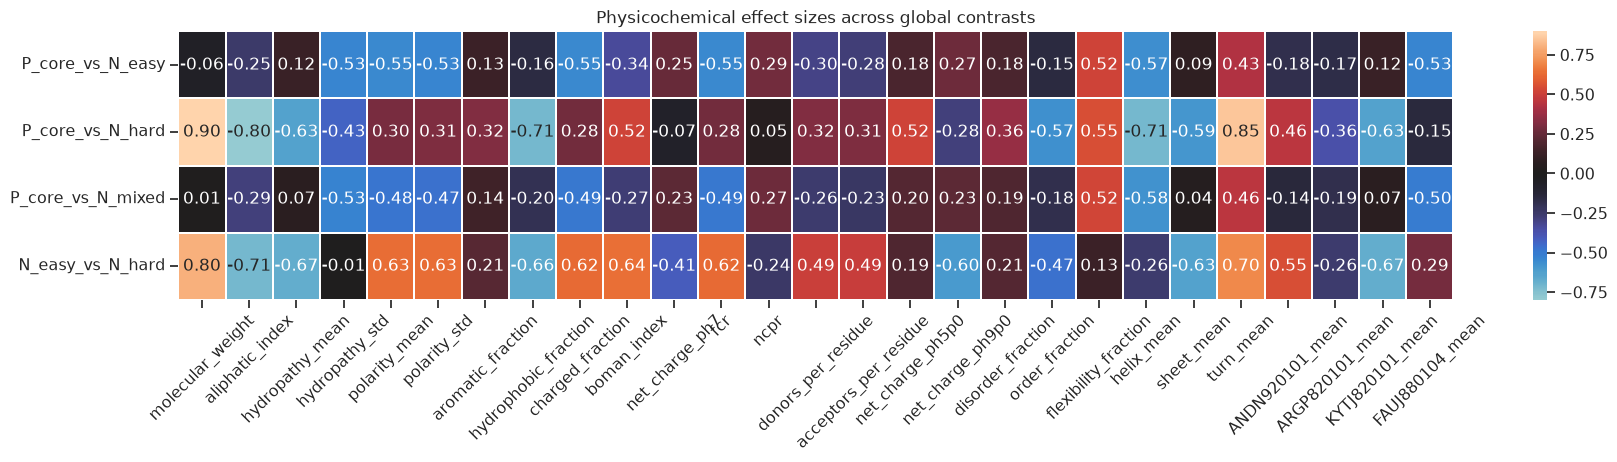

In [17]:
global_heatmap = (
    global_descriptor_effects
    .pivot(
        index="contrast",
        columns="feature",
        values="cliffs_delta",
    )
    .reindex(
        [
            "P_core_vs_N_easy",
            "P_core_vs_N_hard",
            "P_core_vs_N_mixed",
            "N_easy_vs_N_hard",
        ]
    )
    .reindex(
        columns=PHYSICOCHEMICAL_FEATURES
    )
    .rename(
        columns=DISPLAY_NAMES
    )
)

fig, ax = plt.subplots(
    figsize=(18.0, 4.8)
)

sns.heatmap(
    global_heatmap,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(
    "Physicochemical effect sizes across global contrasts"
)

ax.tick_params(
    axis="x",
    rotation=45,
)

fig.tight_layout()

save_figure(
    fig,
    "E3_01_global_physicochemical_cliffs_delta",
)

plt.show()

### Figure E3.2 — Physicochemical effect sizes across clean subtypes

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_02_subtype_physicochemical_cliffs_delta.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_02_subtype_physicochemical_cliffs_delta.pdf


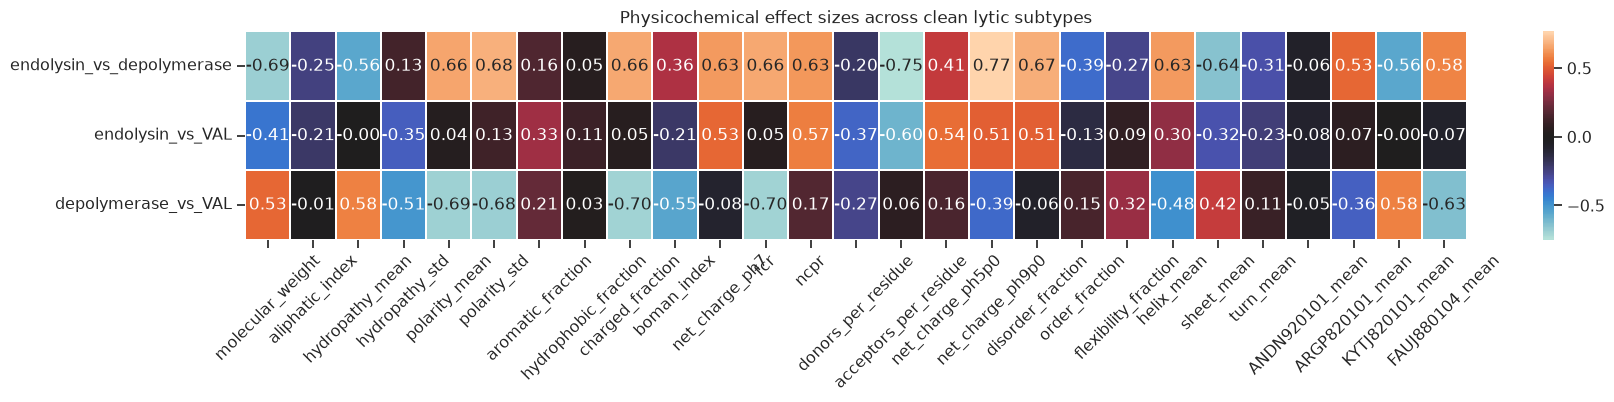

In [18]:
subtype_heatmap = (
    subtype_descriptor_effects
    .pivot(
        index="contrast",
        columns="feature",
        values="cliffs_delta",
    )
    .reindex(
        [
            "endolysin_vs_depolymerase",
            "endolysin_vs_VAL",
            "depolymerase_vs_VAL",
        ]
    )
    .reindex(
        columns=PHYSICOCHEMICAL_FEATURES
    )
    .rename(
        columns=DISPLAY_NAMES
    )
)

fig, ax = plt.subplots(
    figsize=(18.0, 4.2)
)

sns.heatmap(
    subtype_heatmap,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(
    "Physicochemical effect sizes across clean lytic subtypes"
)

ax.tick_params(
    axis="x",
    rotation=45,
)

fig.tight_layout()

save_figure(
    fig,
    "E3_02_subtype_physicochemical_cliffs_delta",
)

plt.show()

### Figure E3.3 — Strongest global physicochemical properties

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_03_top_global_physicochemical_distributions.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_03_top_global_physicochemical_distributions.pdf


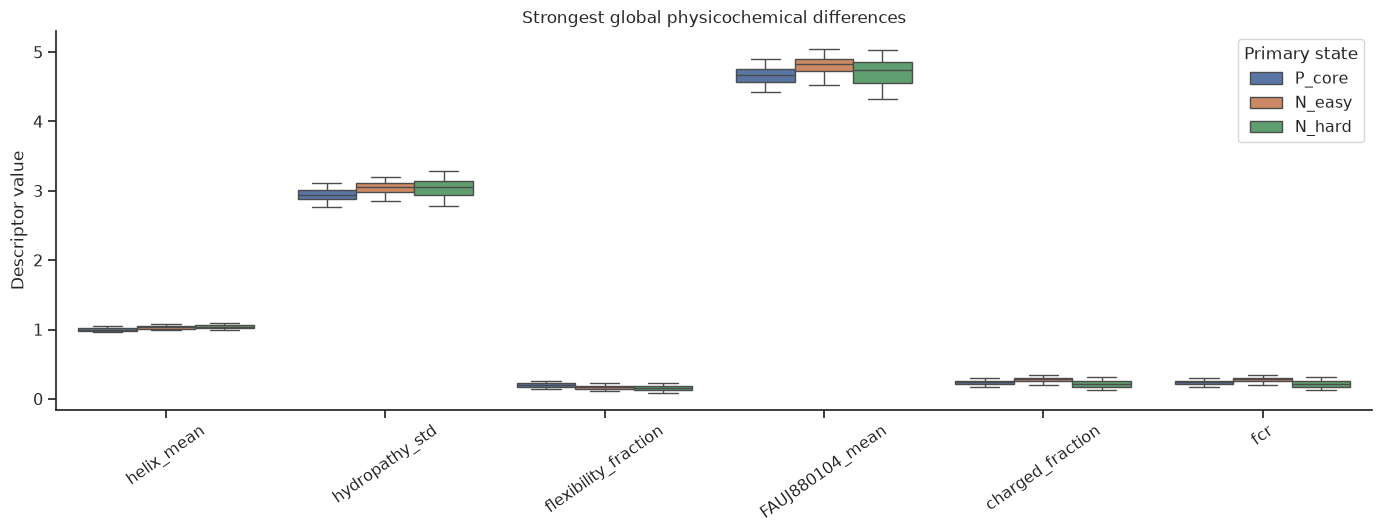

In [19]:
global_primary_ranking = (
    descriptor_rankings.loc[
        descriptor_rankings["scope"].eq(
            "global_target_vs_background"
        )
        & descriptor_rankings[
            "primary_ranking_eligible"
        ]
    ]
    .sort_values(
        "rank_primary_non_length_proxy"
    )
)

top_global_features = (
    global_primary_ranking
    .head(6)["feature"]
    .tolist()
)

global_distribution_data = (
    analysis.loc[
        analysis["sequence_state"].isin(
            ["P_core", "N_easy", "N_hard"]
        ),
        ["sequence_state"] + top_global_features,
    ]
    .melt(
        id_vars="sequence_state",
        value_vars=top_global_features,
        var_name="feature",
        value_name="value",
    )
)

global_distribution_data[
    "feature_label"
] = global_distribution_data[
    "feature"
].map(DISPLAY_NAMES)

fig, ax = plt.subplots(
    figsize=(14.0, 5.5)
)

sns.boxplot(
    data=global_distribution_data,
    x="feature_label",
    y="value",
    hue="sequence_state",
    hue_order=[
        "P_core",
        "N_easy",
        "N_hard",
    ],
    showfliers=False,
    whis=(5, 95),
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("Descriptor value")
ax.set_title(
    "Strongest global physicochemical differences"
)

ax.tick_params(
    axis="x",
    rotation=35,
)

ax.legend(
    title="Primary state"
)

sns.despine()
fig.tight_layout()

save_figure(
    fig,
    "E3_03_top_global_physicochemical_distributions",
)

plt.show()

### Figure E3.4 — Strongest subtype physicochemical properties

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_04_top_subtype_physicochemical_distributions.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_04_top_subtype_physicochemical_distributions.pdf


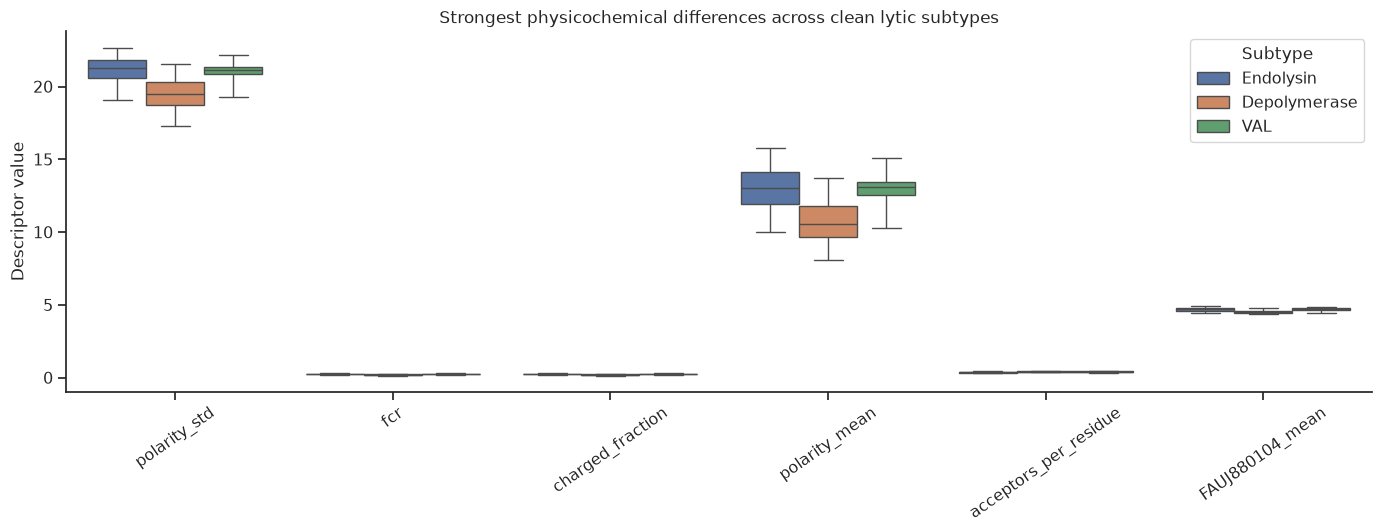

In [20]:
subtype_primary_ranking = (
    descriptor_rankings.loc[
        descriptor_rankings["scope"].eq(
            "clean_subtype_pairwise"
        )
        & descriptor_rankings[
            "primary_ranking_eligible"
        ]
    ]
    .sort_values(
        "rank_primary_non_length_proxy"
    )
)

top_subtype_features = (
    subtype_primary_ranking
    .head(6)["feature"]
    .tolist()
)

subtype_distribution_data = (
    P_CLEAN[
        ["clean_subtype"] + top_subtype_features
    ]
    .melt(
        id_vars="clean_subtype",
        value_vars=top_subtype_features,
        var_name="feature",
        value_name="value",
    )
)

subtype_distribution_data[
    "subtype"
] = subtype_distribution_data[
    "clean_subtype"
].map(SUBTYPE_LABELS)

subtype_distribution_data[
    "feature_label"
] = subtype_distribution_data[
    "feature"
].map(DISPLAY_NAMES)

fig, ax = plt.subplots(
    figsize=(14.0, 5.5)
)

sns.boxplot(
    data=subtype_distribution_data,
    x="feature_label",
    y="value",
    hue="subtype",
    hue_order=[
        "Endolysin",
        "Depolymerase",
        "VAL",
    ],
    showfliers=False,
    whis=(5, 95),
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("Descriptor value")
ax.set_title(
    "Strongest physicochemical differences across clean lytic subtypes"
)

ax.tick_params(
    axis="x",
    rotation=35,
)

ax.legend(
    title="Subtype"
)

sns.despine()
fig.tight_layout()

save_figure(
    fig,
    "E3_04_top_subtype_physicochemical_distributions",
)

plt.show()

### Figure E3.5 — Physicochemical descriptor correlation

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_05_physicochemical_correlation.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_05_physicochemical_correlation.pdf


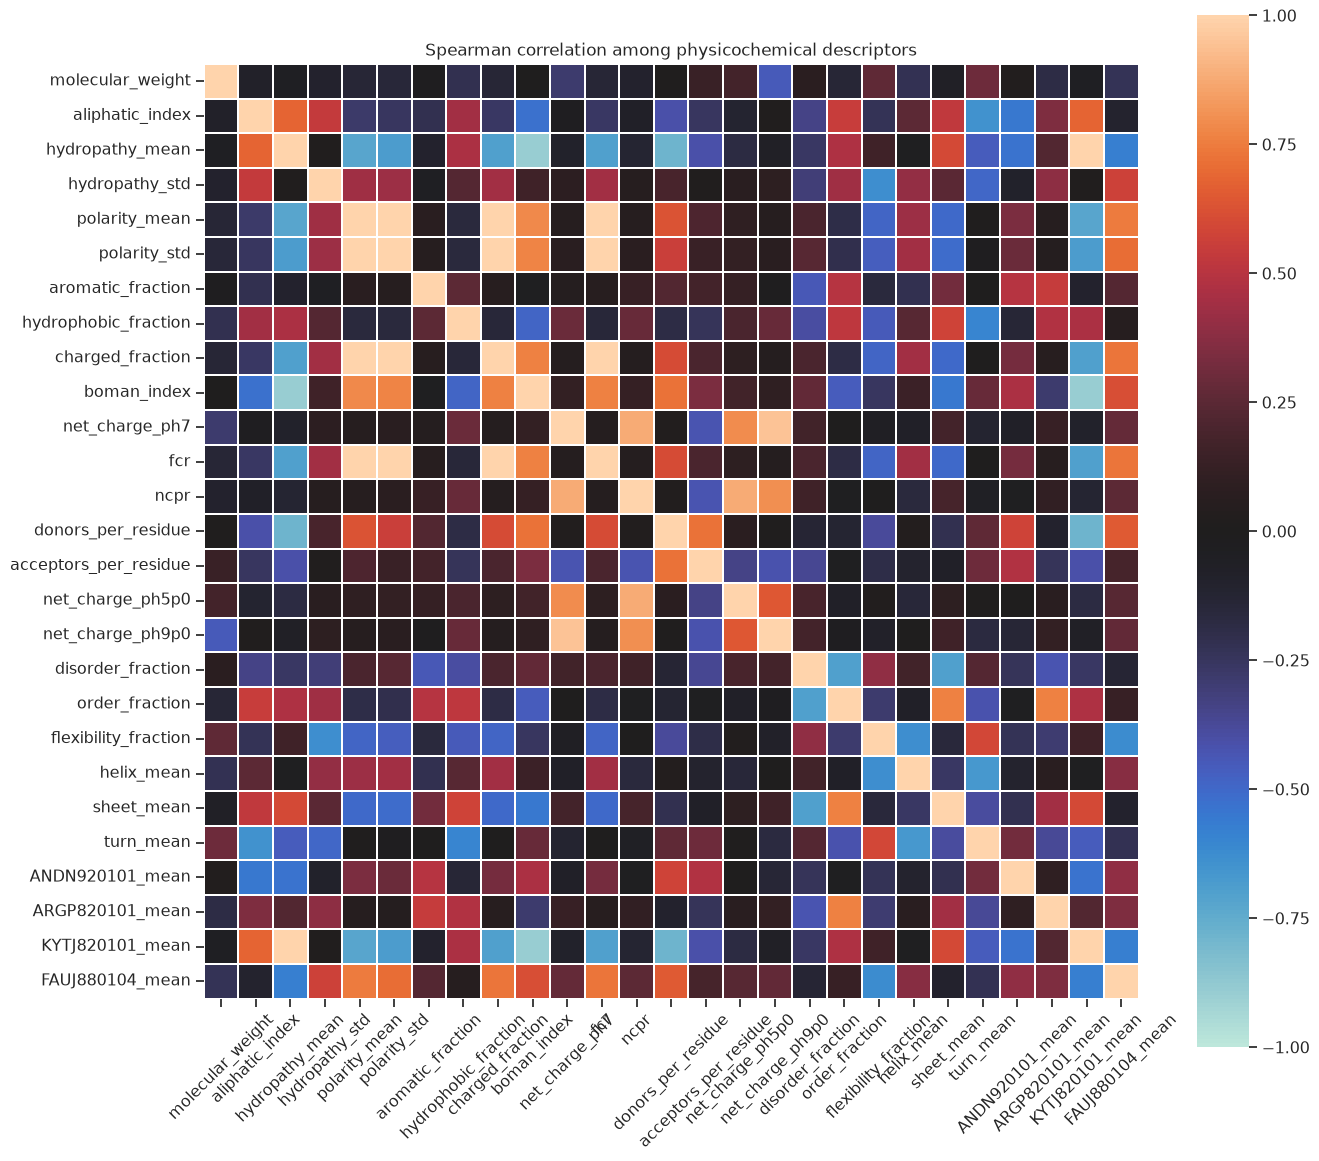

In [21]:
plot_correlation = correlation_matrix.rename(
    index=DISPLAY_NAMES,
    columns=DISPLAY_NAMES,
)

fig, ax = plt.subplots(
    figsize=(14.0, 12.0)
)

sns.heatmap(
    plot_correlation,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.2,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(
    "Spearman correlation among physicochemical descriptors"
)

ax.tick_params(
    axis="x",
    rotation=45,
)

ax.tick_params(
    axis="y",
    rotation=0,
)

fig.tight_layout()

save_figure(
    fig,
    "E3_05_physicochemical_correlation",
)

plt.show()

### Figure E3.6 — Global physicochemical ranking

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_06_global_descriptor_ranking.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_06_global_descriptor_ranking.pdf


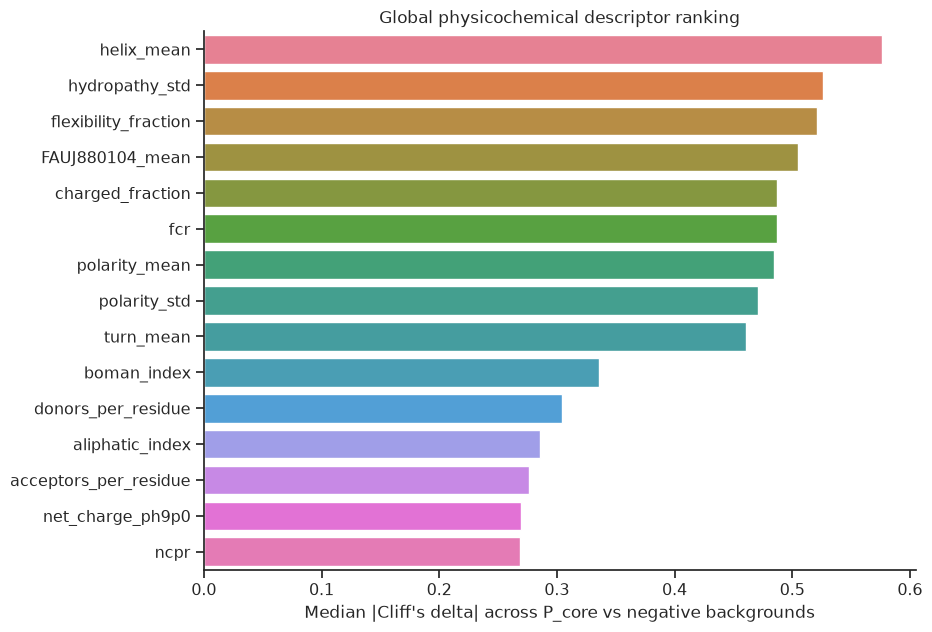

In [22]:
plot_global_ranking = (
    global_primary_ranking
    .head(15)
    .copy()
)

plot_global_ranking[
    "feature_label"
] = plot_global_ranking[
    "feature"
].map(DISPLAY_NAMES)

fig, ax = plt.subplots(
    figsize=(9.5, 6.5)
)

sns.barplot(
    data=plot_global_ranking,
    y="feature_label",
    x="median_abs_cliffs_delta",
    hue="feature_label",
    dodge=False,
    legend=False,
    ax=ax,
)

ax.set_xlabel(
    "Median |Cliff's delta| across P_core vs negative backgrounds"
)
ax.set_ylabel("")
ax.set_title(
    "Global physicochemical descriptor ranking"
)

sns.despine()
fig.tight_layout()

save_figure(
    fig,
    "E3_06_global_descriptor_ranking",
)

plt.show()

### Figure E3.7 — Clean-subtype physicochemical ranking

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_07_subtype_descriptor_ranking.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_07_subtype_descriptor_ranking.pdf


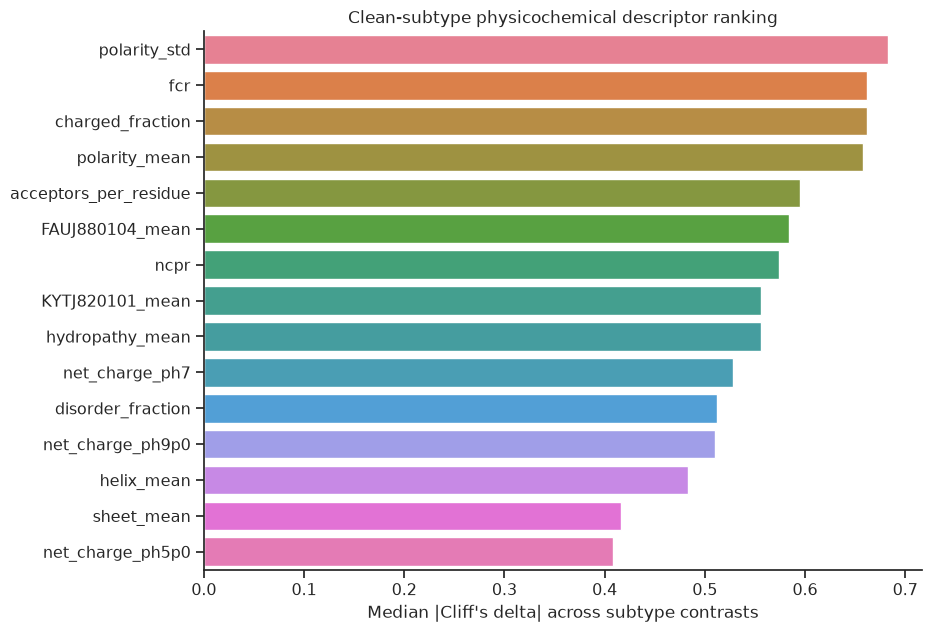

In [23]:
plot_subtype_ranking = (
    subtype_primary_ranking
    .head(15)
    .copy()
)

plot_subtype_ranking[
    "feature_label"
] = plot_subtype_ranking[
    "feature"
].map(DISPLAY_NAMES)

fig, ax = plt.subplots(
    figsize=(9.5, 6.5)
)

sns.barplot(
    data=plot_subtype_ranking,
    y="feature_label",
    x="median_abs_cliffs_delta",
    hue="feature_label",
    dodge=False,
    legend=False,
    ax=ax,
)

ax.set_xlabel(
    "Median |Cliff's delta| across subtype contrasts"
)
ax.set_ylabel("")
ax.set_title(
    "Clean-subtype physicochemical descriptor ranking"
)

sns.despine()
fig.tight_layout()

save_figure(
    fig,
    "E3_07_subtype_descriptor_ranking",
)

plt.show()

### Figure E3.8 — Association of physicochemical descriptors with sequence length

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_08_descriptor_length_association.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/figures/E3_08_descriptor_length_association.pdf


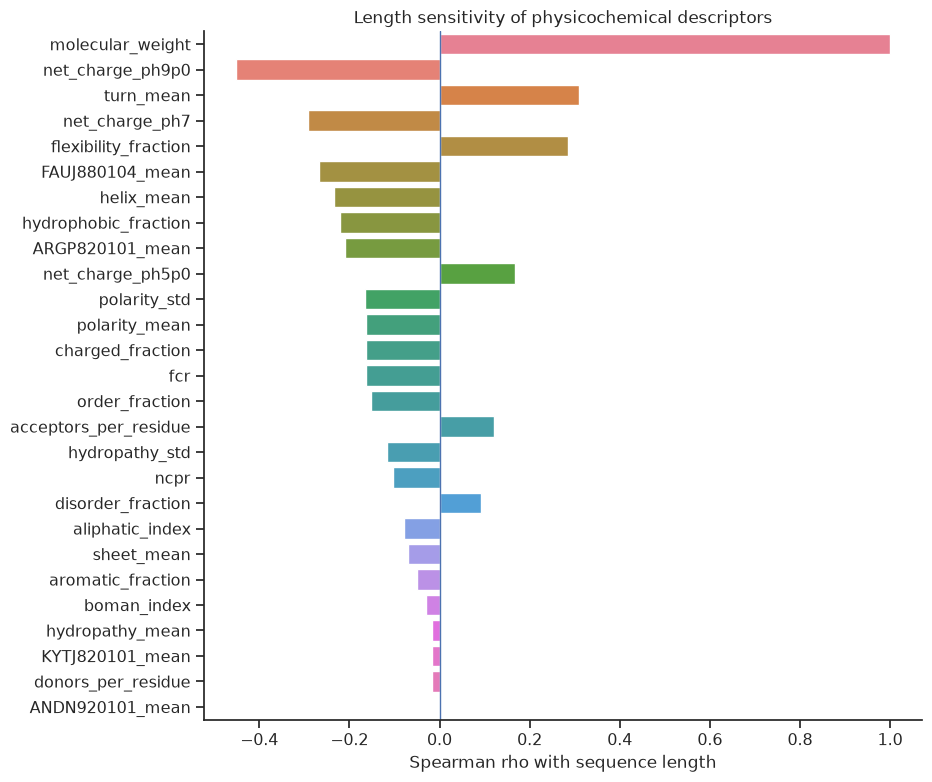

In [24]:
plot_length_association = (
    descriptor_length_association
    .sort_values(
        "abs_spearman_rho_with_sequence_length",
        ascending=False,
    )
    .copy()
)

plot_length_association[
    "feature_label"
] = plot_length_association[
    "feature"
].map(DISPLAY_NAMES)

fig, ax = plt.subplots(
    figsize=(9.5, 8.0)
)

sns.barplot(
    data=plot_length_association,
    y="feature_label",
    x="spearman_rho_with_sequence_length",
    hue="feature_label",
    dodge=False,
    legend=False,
    ax=ax,
)

ax.axvline(
    0,
    linewidth=1,
)

ax.set_xlabel(
    "Spearman rho with sequence length"
)
ax.set_ylabel("")
ax.set_title(
    "Length sensitivity of physicochemical descriptors"
)

sns.despine()
fig.tight_layout()

save_figure(
    fig,
    "E3_08_descriptor_length_association",
)

plt.show()

## 14. Final closure checks

In [25]:
assert len(physicochemical) == 442_329
assert physicochemical["sequence_uid"].is_unique

assert len(PHYSICOCHEMICAL_FEATURES) == 27
assert len(PRIMARY_RANKING_FEATURES) == 26

# No AAC or E2 entropy/complexity variables are allowed in E3.
assert not any(
    feature.startswith("aac_")
    for feature in PHYSICOCHEMICAL_FEATURES
)

assert (
    "global_basic_shannon_entropy"
    not in PHYSICOCHEMICAL_FEATURES
)

assert not any(
    feature.startswith("entropy_complexity_")
    for feature in PHYSICOCHEMICAL_FEATURES
)

assert not physicochemical[
    PHYSICOCHEMICAL_FEATURES
].isna().any().any()

assert len(P) == 11_867
assert len(N_EASY) == 54_711
assert len(N_HARD) == 4_327
assert len(N_MIXED) == 59_038

assert int(
    P_CLEAN["clean_subtype"]
    .eq("endolysin")
    .sum()
) == 9_888

assert int(
    P_CLEAN["clean_subtype"]
    .eq("depolymerase")
    .sum()
) == 712

assert int(
    P_CLEAN["clean_subtype"]
    .eq(
        "virion_associated_lytic_enzyme"
    )
    .sum()
) == 241

assert len(
    global_descriptor_effects
) == 4 * 27

assert len(
    subtype_descriptor_effects
) == 3 * 27

assert len(
    descriptor_omnibus
) == 2 * 27

assert len(
    descriptor_rankings
) == 2 * 27

required_tables = [
    FEATURE_PATH,
    FEATURE_MANIFEST_PATH,
    METADATA_PATH,
    STATISTICS_PATH,
    OMNIBUS_PATH,
    GLOBAL_EFFECTS_PATH,
    SUBTYPE_EFFECTS_PATH,
    CORRELATIONS_PATH,
    REDUNDANCY_PATH,
    LENGTH_ASSOCIATION_PATH,
    RANKINGS_PATH,
]

for path in required_tables:
    assert path.is_file(), (
        f"Missing E3 output: {path}"
    )

expected_figure_stems = [
    "E3_01_global_physicochemical_cliffs_delta",
    "E3_02_subtype_physicochemical_cliffs_delta",
    "E3_03_top_global_physicochemical_distributions",
    "E3_04_top_subtype_physicochemical_distributions",
    "E3_05_physicochemical_correlation",
    "E3_06_global_descriptor_ranking",
    "E3_07_subtype_descriptor_ranking",
    "E3_08_descriptor_length_association",
]

for stem in expected_figure_stems:
    for suffix in [".png", ".pdf"]:
        figure_path = (
            FIGURE_DIR
            / f"{stem}{suffix}"
        )

        assert figure_path.is_file(), (
            f"Missing E3 figure: {figure_path}"
        )

print("=" * 72)
print(
    "PASS — E3 physicochemical landscape completed."
)
print("=" * 72)

print()
print(f"Descriptor table         : {FEATURE_PATH}")
print(f"Feature manifest         : {FEATURE_MANIFEST_PATH}")
print(f"Descriptor statistics    : {STATISTICS_PATH}")
print(f"Omnibus tests            : {OMNIBUS_PATH}")
print(f"Global effects           : {GLOBAL_EFFECTS_PATH}")
print(f"Subtype effects          : {SUBTYPE_EFFECTS_PATH}")
print(f"Correlations             : {CORRELATIONS_PATH}")
print(f"Redundancy pairs         : {REDUNDANCY_PATH}")
print(f"Length associations      : {LENGTH_ASSOCIATION_PATH}")
print(f"Descriptor rankings      : {RANKINGS_PATH}")
print(f"Figures                  : {FIGURE_DIR}")

PASS — E3 physicochemical landscape completed.

Descriptor table         : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/physicochemical_descriptors.parquet
Feature manifest         : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/physicochemical_feature_manifest.tsv
Descriptor statistics    : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/descriptor_statistics.tsv
Omnibus tests            : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/descriptor_omnibus.tsv
Global effects           : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/global_descriptor_effects.tsv
Subtype effects          : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E3/subtype_descriptor_effects.tsv
Correlations             : /home/david/Desktop/co